# Flaky-Test Patch Generation with Qwen2.5-Coder-3B

This experiment fine-tunes a code language model to generate developer-style
patches for flaky Java/Maven tests. QLoRA adapts the pinned
`unsloth/Qwen2.5-Coder-3B-Instruct-bnb-4bit` checkpoint using frozen NF4
weights and FP16 compute on a Colab T4.

ReproFlake contains 1,115 test instances across 140 projects. The canonical
project-disjoint split assigns 869/64/182 tests to training/validation/test.
Source context is selected from the original failing snapshot, independently
of the reference patch. Fixed code, fixing references, and inferred rationales
are excluded from prompts; missing evidence is omitted.

The comparison uses identical prompts and decoding for the un-tuned base and
trained adapter. Reported scores measure reference-patch similarity, not
execution-validated repair success.

## 1. Environment and storage

Use a T4 runtime. Place the prepared `repair_pairs.zip` in
`MyDrive/reproflake/`. Checkpoints and trained adapter weights are saved to
that Drive folder; raw source archives are not needed here.

In [ ]:
import gc
import json
import os
import subprocess
import sys
import tempfile
from datetime import datetime, timezone
from importlib.metadata import distributions, version
from pathlib import Path, PurePosixPath
from zipfile import ZipFile
import stat

import torch
from google.colab import drive

if not torch.cuda.is_available() or "T4" not in torch.cuda.get_device_name(0):
    raise RuntimeError("This notebook requires a Colab T4 GPU.")
print(torch.cuda.get_device_name(0), "| CUDA", torch.version.cuda)

# Attach Google Drive and set working directory
drive.mount("/content/drive")
DRIVE = Path("/content/drive/MyDrive/reproflake")
DATA_ARCHIVE = DRIVE / "repair_pairs.zip"
if "WORK" not in globals() or not WORK.is_dir():
    WORK = Path(tempfile.mkdtemp(prefix="repair-training-"))
os.chdir(WORK)
sys.path.insert(0, str(WORK))

Tesla T4 | CUDA 13.0
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Install dependencies in Colab

In [7]:
%%writefile requirements-training.txt
# Install with Colab's preinstalled CUDA build of PyTorch and matching wheels.
transformers==4.57.6
peft==0.18.1
accelerate==1.12.0
unidiff==0.7.5
unsloth==2026.1.4
unsloth-zoo==2026.1.4
bitsandbytes==0.49.2
trl==0.24.0
datasets==4.3.0

Writing requirements-training.txt


In [8]:
installed = {dist.metadata["Name"].lower() for dist in distributions()}
constraints = [f"torch=={version('torch')}"]
for package in ("torchvision", "triton"):
    if package in installed:
        constraints.append(f"{package}=={version(package)}")
Path("torch-constraints.txt").write_text("\n".join(constraints) + "\n")
%pip install -q -r requirements-training.txt -c torch-constraints.txt

## 2. Data safeguards and experiment settings

The following labeled cells define one embedded helper module. The default budgets are 3,072 sequence tokens and 2,048 patch tokens; the remaining 1,024 tokens are reserved for original-only context.  

### Partition and checksum validation

In [9]:
%%writefile repair_helpers.py
"""ReproFlake data safeguards, QLoRA initialization, and static repair metrics."""

import hashlib
import importlib.metadata
import json
import logging
import math
import random
import re
import statistics
from collections import Counter, defaultdict
from contextlib import nullcontext
from dataclasses import dataclass
from pathlib import Path, PurePosixPath
from time import perf_counter

from unidiff import PatchSet, UnidiffParseError

LOG = logging.getLogger(__name__)


SPLITS = ("train", "validation", "test")

EXPECTED_COUNTS = {
    "train": (98, 869, 222),
    "validation": (21, 64, 32),
    "test": (21, 182, 46),
}

BUNDLE_VERSION = 1

def digest(payload: bytes) -> str:
    return hashlib.sha256(payload).hexdigest()

def file_digest(path: Path) -> str:
    with path.open("rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest()

def read_json(path: Path):
    with path.open(encoding="utf-8") as stream:
        return json.load(stream)

def write_json(path: Path, value) -> None:
    path.write_text(
        json.dumps(value, indent=2, allow_nan=False) + "\n", encoding="utf-8"
    )

def read_jsonl(path: Path) -> list[dict]:
    with path.open(encoding="utf-8") as stream:
        return [json.loads(line) for line in stream]

def write_jsonl(path: Path, rows) -> None:
    with path.open("w", encoding="utf-8") as stream:
        for row in rows:
            stream.write(json.dumps(row, ensure_ascii=False, allow_nan=False) + "\n")

def index(rows, key: str) -> dict:
    result = {}
    for row in rows:
        value = row[key]
        if not value or value in result:
            raise ValueError(f"Missing or duplicate {key}: {value!r}")
        result[value] = row
    return result

@dataclass(frozen=True)
class Assignment:
    case_id: str
    project: str
    archive_id: str
    split: str

    @classmethod
    def from_row(cls, row: dict):
        return cls(**{name: row[name] for name in cls.__dataclass_fields__})

def validate_assignments(rows, *, require_full: bool = True):
    cases = {}
    projects = {}
    archives = {}
    for row in rows:
        case = Assignment.from_row(row)
        if any(
            not isinstance(value, str) or not value.strip()
            for value in vars(case).values()
        ):
            raise ValueError(f"Invalid case assignment: {case}")
        if case.case_id in cases or case.split not in SPLITS:
            raise ValueError(f"Duplicate case or unknown split: {case}")
        if projects.setdefault(case.project.casefold(), case.split) != case.split:
            raise ValueError(f"Project crosses partitions: {case.project}")
        archive_owner = (case.project, case.split)
        if archives.setdefault(case.archive_id, archive_owner) != archive_owner:
            raise ValueError(f"Inconsistent archive ownership: {case.archive_id}")
        cases[case.case_id] = case
    for split in SPLITS:
        subset = [case for case in cases.values() if case.split == split]
        counts = (
            len({case.project.casefold() for case in subset}),
            len(subset),
            len({case.archive_id for case in subset}),
        )
        if not subset or (require_full and counts != EXPECTED_COUNTS[split]):
            raise ValueError(
                f"Unexpected {split} split (projects, cases, archives): {counts}"
            )
    return cases

def validate_repair_splits(target_hashes: dict[str, str], cases: dict[str, Assignment]):
    splits = {case.archive_id: case.split for case in cases.values()}
    seen = {}
    for archive, checksum in target_hashes.items():
        if archive not in splits:
            raise ValueError(f"Target archive is not assigned: {archive}")
        if seen.setdefault(checksum, splits[archive]) != splits[archive]:
            raise ValueError(f"Identical reference patch crosses partitions: {archive}")

class Bundle:
    def __init__(self, path: Path):
        self.path = path
        self.manifest = read_json(path / "manifest.json")
        if self.manifest["version"] != BUNDLE_VERSION:
            raise ValueError(
                "Unsupported prepared bundle version. Re-run data preparation."
            )
        self.fingerprint = file_digest(path / "manifest.json")
        self.cases = validate_assignments(self._read("assignments.jsonl"))
        validate_repair_splits(self.manifest["target_hashes"], self.cases)

    def _read(self, name: str):
        path = self.path / name
        if file_digest(path) != self.manifest["files"][name]:
            raise ValueError(f"Prepared data checksum mismatch: {path}")
        return read_jsonl(path)

    def inputs(self, split: str) -> list[dict]:
        if split not in SPLITS:
            raise ValueError(f"Unknown split: {split}")
        rows = self._read(f"{split}_inputs.jsonl")
        for row in index(rows, "case_id").values():
            case = Assignment.from_row(row)
            if (
                self.cases.get(case.case_id) != case
                or case.split != split
                or case.archive_id not in self.manifest["target_hashes"]
            ):
                raise ValueError(f"Input is inconsistent with prepared split: {case}")
        return rows

    def targets(self, split: str, inputs: list[dict]) -> dict[str, str]:
        if split not in SPLITS:
            raise ValueError(f"Unknown split: {split}")
        expected = {row["archive_id"] for row in inputs}
        rows = index(self._read(f"{split}_targets.jsonl"), "archive_id")
        if set(rows) != expected:
            raise ValueError(f"Input/target archive coverage differs in {split}")
        targets = {}
        for archive, row in rows.items():
            if (
                digest(row["patch"].encode("utf-8"))
                != self.manifest["target_hashes"][archive]
            ):
                raise ValueError(f"Target hash mismatch: {archive}")
            targets[archive] = row["patch"]
        return targets


Writing repair_helpers.py


### Original-only prompts and completion labels

In [10]:
%%writefile -a repair_helpers.py
SYSTEM = (
    "Repair the reported flaky Java test while preserving its intended assertions. "
    "Return only a unified diff with file headers and all hunks. "
    "Do not include Markdown fences or an explanation."
)

ENV_FIELDS = (
    "Maven module",
    "Java version",
    "Configured repetitions",
    "NonDex seed",
    "Reported polluter",
    "Published original outcomes",
)

@dataclass(frozen=True)
class PackedPrompt:
    ids: list[int]
    included_files: int
    excerpted_files: int
    omitted_files: int

def pack_prompt(tokenizer, row: dict, budget: int) -> PackedPrompt:
    def safe(text: str) -> str:
        for token in tokenizer.all_special_tokens:
            text = text.replace(token, token[:1] + "\\" + token[1:])
        return text

    def encode(message: str) -> list[int]:
        return tokenizer.apply_chat_template(
            [
                {"role": "system", "content": SYSTEM},
                {"role": "user", "content": safe(message)},
            ],
            tokenize=True,
            return_dict=False,
            add_generation_prompt=True,
            tokenizer_kwargs={"verbose": False},
        )

    context = f"Failing test: {row['test']}\n"
    environment = row["environment"]
    for key in ENV_FIELDS:
        if key in environment:
            context += f"{key}: {environment[key]}\n"
    files = row["files"]
    if not files or files[0]["kind"] != "failing test":
        raise ValueError(f"No original failing test source: {row['case_id']}")
    ids = encode(context)
    if len(ids) >= budget:
        raise ValueError(
            f"Prompt budget does not fit the test identity and metadata: {row['case_id']}"
        )

    def fit(source: dict, limit: int):
        prefix = f"\n[{source['kind']}: {source['path']}]"
        lines = source["text"].splitlines(keepends=True)
        if not lines:
            return None
        text = f"{prefix}\n{source['text']}\n"
        encoded = encode(context + text)
        if len(encoded) <= limit:
            return text, encoded, False
        anchor = 0
        if method := source.get("method"):
            pattern = re.compile(rf"\b{re.escape(method)}\s*\(")
            anchor = next(
                (i for i, line in enumerate(lines) if pattern.search(line)), 0
            )
        # Preserve a contiguous original line window around the named test.
        start = max(0, anchor - 12)
        best = None
        lower, upper = anchor - start + 1, len(lines) - start
        while lower <= upper:
            count = (lower + upper) // 2
            text = (
                f"{prefix} (excerpt, original lines {start + 1}-{start + count})\n"
                + "".join(lines[start : start + count])
                + "\n"
            )
            encoded = encode(context + text)
            if len(encoded) <= limit:
                best = (text, encoded, True)
                lower = count + 1
            else:
                upper = count - 1
        if best is None and start < anchor:
            text = f"{prefix} (excerpt, original line {anchor + 1})\n{lines[anchor]}\n"
            encoded = encode(context + text)
            if len(encoded) <= limit:
                best = (text, encoded, True)
        return best

    primary_limit = budget
    if len(files) > 1:
        primary_limit = len(ids) + (budget - len(ids)) * 3 // 4
    primary = fit(files[0], primary_limit)
    if primary is None and primary_limit != budget:
        primary = fit(files[0], budget)
    if primary is None:
        raise ValueError(
            f"Prompt budget does not fit a failing source line: {row['case_id']}"
        )
    addition, ids, excerpt = primary
    context += addition
    included, excerpted = 1, int(excerpt)
    for offset, source in enumerate(files[1:], 1):
        share = (budget - len(ids)) // (len(files) - offset)
        fitted = fit(source, len(ids) + share)
        if fitted is not None:
            addition, ids, excerpt = fitted
            context += addition
            included += 1
            excerpted += int(excerpt)
    return PackedPrompt(ids, included, excerpted, len(files) - included)

def patch_token_ids(tokenizer, patch: str) -> list[int]:
    return tokenizer.encode(patch, add_special_tokens=False, verbose=False)

def training_sequence(tokenizer, prompt: PackedPrompt, patch: str, patch_budget: int):
    patch_ids = patch_token_ids(tokenizer, patch)
    if not patch_ids or len(patch_ids) + 1 > patch_budget:
        return None, len(patch_ids) + 1, "full target exceeds token budget or is empty"
    if set(patch_ids).intersection(tokenizer.all_special_ids):
        return None, len(patch_ids) + 1, "target contains a model control token"
    completion = patch_ids + [tokenizer.eos_token_id]
    return (
        {
            "input_ids": prompt.ids + completion,
            "labels": [-100] * len(prompt.ids) + completion,
        },
        len(completion),
        None,
    )


Appending to repair_helpers.py


### Pinned NF4 model and T4 memory limits

In [11]:
%%writefile -a repair_helpers.py
UNSLOTH_QLORA = "unsloth_qlora"

GIB = 1024**3

def read_config(path: Path) -> dict:
    config = read_json(path)
    if (
        config["backend"] != UNSLOTH_QLORA
        or not config["prequantized"]
        or config["trainer"] != "sft"
        or config["model_id"] != "unsloth/Qwen2.5-Coder-3B-Instruct-bnb-4bit"
    ):
        raise ValueError(
            "Only the prequantized Qwen2.5-Coder-3B SFT profile is supported."
        )
    if "checkpoint_steps" in config and (
        type(config["checkpoint_steps"]) is not int or config["checkpoint_steps"] < 1
    ):
        raise ValueError("checkpoint_steps must be a positive integer.")
    if config["precision"] != "fp16":
        raise ValueError("The T4 profile requires fp16 compute.")
    if not re.fullmatch(r"[a-f0-9]{40}", config["revision"]):
        raise ValueError("revision must be an immutable Hugging Face commit SHA")
    if not 2 <= config["max_patch_tokens"] < config["max_seq_length"]:
        raise ValueError("Require 2 <= max_patch_tokens < max_seq_length")
    if "cuda_memory" in config:
        memory = config["cuda_memory"]
        keys = {"max_gib", "reserve_gib", "min_free_gib"}
        if (
            not isinstance(memory, dict)
            or set(memory) != keys
            or any(
                type(value) not in {int, float} or not 0 < value < 1024
                for value in memory.values()
            )
            or memory["reserve_gib"] >= memory["min_free_gib"]
        ):
            raise ValueError(
                "Invalid cuda_memory budget: require positive max, reserve and minimum free GiB, with reserve below minimum free."
            )
    if type(config["evaluation"]["bootstrap_samples"]) is not int or config["evaluation"]["bootstrap_samples"] < 100:
        raise ValueError("At least 100 project bootstrap samples are required.")
    return config

def cuda_settings(precision: str, *, memory: dict | None = None):
    import torch

    if not torch.cuda.is_available():
        raise RuntimeError(
            "CUDA is required. In Colab select Runtime > Change runtime type and choose a GPU."
        )
    name = torch.cuda.get_device_name(0)
    if "T4" not in name:
        raise RuntimeError(f"This experiment targets a T4; found {name}.")
    if precision != "fp16":
        raise ValueError("The T4 profile requires fp16 compute.")
    dtype = torch.float16
    hardware = {
        "gpu": name,
        "gpu_memory_bytes": torch.cuda.get_device_properties(0).total_memory,
        "cuda": torch.version.cuda,
        "dtype": str(dtype),
    }
    if memory is not None:
        free, total = torch.cuda.mem_get_info(0)
        if free < memory["min_free_gib"] * GIB:
            raise RuntimeError(
                f"{name} has {free / GIB:.2f} GiB free; this profile requires at least "
                f"{memory['min_free_gib']} GiB. Release unused GPU allocations before retrying."
            )
        cap = int(min(memory["max_gib"] * GIB, free - memory["reserve_gib"] * GIB))
        torch.cuda.set_per_process_memory_fraction(cap / total, device=0)
        hardware.update(
            cuda_free_at_start_bytes=free,
            pytorch_allocator_limit_bytes=cap,
        )
    return dtype, hardware

def package_versions(
    config: dict, *, training: bool = False, dry_run: bool = False
) -> dict:
    names = ["torch", "transformers", "peft", "accelerate", "unidiff"]
    if not dry_run:
        names.append("bitsandbytes")
        if training:
            names.extend(["unsloth", "unsloth-zoo", "trl", "triton", "xformers"])
            names.append("datasets")
    return {name: importlib.metadata.version(name) for name in names}

def quantization_settings(config: dict) -> dict:
    return {
        "load_in_4bit": True,
        "bnb_4bit_quant_type": "nf4",
        "bnb_4bit_use_double_quant": True,
        "bnb_4bit_compute_dtype": config["precision"],
        "llm_int8_skip_modules": None,
    }

def bnb_config(config: dict, dtype):
    from transformers import BitsAndBytesConfig

    settings = quantization_settings(config)
    settings["bnb_4bit_compute_dtype"] = dtype
    return BitsAndBytesConfig(**settings)

def require_4bit(model):
    if not getattr(model, "is_loaded_in_4bit", False):
        raise RuntimeError(
            "The requested NF4 Qwen checkpoint was not loaded in 4-bit mode."
        )
    return model

def set_serialized_4bit_compute_dtype(model, config: dict, dtype):
    from bitsandbytes.nn import Linear4bit

    layers = [module for module in model.modules() if isinstance(module, Linear4bit)]
    if not layers or any(
        layer.weight.quant_state is None
        or layer.weight.quant_state.quant_type != "nf4"
        or not layer.weight.quant_state.nested
        for layer in layers
    ):
        raise RuntimeError(
            "The serialized checkpoint did not yield double-quantized NF4 layers."
        )
    # Transformers uses the saved BNB config in preference to loading arguments.
    for layer in layers:
        layer.compute_dtype = dtype
        layer.compute_type_is_set = True
    model.config.quantization_config = bnb_config(config, dtype)
    return model

def load_model(config, dtype, fast_model):
    model, _ = fast_model.from_pretrained(
        model_name=config["model_id"], revision=config["revision"],
        max_seq_length=config["max_seq_length"], dtype=dtype,
        load_in_4bit=True, full_finetuning=False, use_exact_model_name=True,
        device_map={"": 0}, trust_remote_code=False, use_safetensors=True,
        use_gradient_checkpointing=False,
    )
    return set_serialized_4bit_compute_dtype(require_4bit(model), config, dtype)

def load_training_model(config, dtype, fast_model):
    if fast_model is None:
        raise RuntimeError("Initialize Unsloth before loading the training model.")
    model = load_model(config, dtype, fast_model)
    checkpointing = "unsloth" if config["training"]["gradient_checkpointing"] else False
    model = fast_model.get_peft_model(
        model, **config["lora"], bias="none", random_state=config["seed"],
        use_gradient_checkpointing=checkpointing,
    )
    model.config.use_cache = False
    return model


Appending to repair_helpers.py


### Repair-level sampling and padding

In [12]:
%%writefile -a repair_helpers.py
def examples(
    bundle: Bundle,
    split: str,
    tokenizer,
    config: dict,
    limit: int | None,
    *,
    longest: bool = False,
):
    inputs = bundle.inputs(split)
    targets = bundle.targets(split, inputs)
    by_repair = {}
    for row in sorted(inputs, key=lambda row: (row["archive_id"], row["case_id"])):
        checksum = bundle.manifest["target_hashes"][row["archive_id"]]
        by_repair.setdefault(checksum, row)
    selected, audit = [], []
    prompt_budget = config["max_seq_length"] - config["max_patch_tokens"]
    for row in by_repair.values():
        patch = targets[row["archive_id"]]
        parsed = PatchSet(patch)
        prompt = pack_prompt(tokenizer, row, prompt_budget)
        example, token_count, reason = training_sequence(
            tokenizer, prompt, patch, config["max_patch_tokens"]
        )
        audit.append(
            {
                "split": split,
                "case_id": row["case_id"],
                "project": row["project"],
                "archive_id": row["archive_id"],
                "patch_files": len(parsed),
                "patch_hunks": sum(map(len, parsed)),
                "patch_tokens_with_eos": token_count,
                "prompt_tokens": len(prompt.ids),
                "excerpted_files": prompt.excerpted_files,
                "omitted_files": prompt.omitted_files,
                "disposition": reason or "included",
            }
        )
        if example is not None:
            selected.append((example, audit[-1]))
            if not longest and limit is not None and len(selected) == limit:
                break
    if longest:
        selected.sort(key=lambda pair: len(pair[0]["input_ids"]), reverse=True)
        for _, record in selected[limit:]:
            record["disposition"] = "omitted from longest-example sample"
        selected = selected[:limit]
    return [example for example, _ in selected], audit

class CausalCollator:
    def __init__(self, pad_id: int):
        self.pad_id = pad_id

    def __call__(self, features):
        import torch

        width = max(len(row["input_ids"]) for row in features)
        ids = torch.full((len(features), width), self.pad_id, dtype=torch.long)
        labels = torch.full_like(ids, -100)
        mask = torch.zeros_like(ids)
        for i, row in enumerate(features):
            length = len(row["input_ids"])
            ids[i, :length] = torch.tensor(row["input_ids"], dtype=torch.long)
            labels[i, :length] = torch.tensor(row["labels"], dtype=torch.long)
            mask[i, :length] = 1
        return {"input_ids": ids, "labels": labels, "attention_mask": mask}


Appending to repair_helpers.py


### Normalized diffs and location-aware scoring

In [13]:
%%writefile -a repair_helpers.py
METRICS = (
    "exact_patch_match",
    "normalized_patch_match",
    "parsed_text_diff",
    "changed_line_f1",
    "located_changed_line_f1",
    "hit_token_limit",
)

def canonical(patch: str) -> str:
    return patch.replace("\r\n", "\n").rstrip("\n")

def normalized_path(path):
    if path == "/dev/null":
        return path
    for prefix in ("Flaky/", "Fixed/", "a/", "b/"):
        if path.startswith(prefix):
            path = path[len(prefix) :]
            break
    parts = PurePosixPath(path)
    if not path or parts.is_absolute() or ".." in parts.parts or "\\" in path or "\x00" in path:
        raise ValueError(f"Unsafe patch path: {path!r}")
    return parts.as_posix()

def parsed_diff(text):
    if not text.startswith(("diff ", "--- ")):
        raise ValueError("Output does not start with a unified-diff header.")
    patch = PatchSet(text)
    if not patch:
        raise ValueError("Patch has no changed files.")
    for file in patch:
        normalized_path(file.source_file)
        normalized_path(file.target_file)
        if file.is_binary_file or not file:
            raise ValueError("Patch contains a binary file or a file without textual hunks.")
    return patch

def structural_patch(patch):
    return tuple(sorted(
        (
            normalized_path(file.source_file),
            normalized_path(file.target_file),
            tuple(
                (
                    hunk.source_start, hunk.source_length,
                    hunk.target_start, hunk.target_length,
                    tuple((line.line_type, line.value.rstrip("\r\n")) for line in hunk),
                )
                for hunk in file
            ),
        )
        for file in patch
    ))

def edit_lines(patch, *, located=False):
    edits = Counter()
    for file in patch:
        path = normalized_path(file.target_file if file.is_added_file else file.source_file)
        for hunk in file:
            for line in hunk:
                if line.is_added or line.is_removed:
                    position = line.target_line_no if line.is_added else line.source_line_no
                    key = (path, line.line_type, line.value.rstrip("\r\n"))
                    if located:
                        key += (position,)
                    edits[key] += 1
    return edits

def changed_lines(text):
    try:
        return edit_lines(parsed_diff(text)) or None
    except (UnidiffParseError, ValueError):
        return None

def edit_f1(candidate, reference):
    denominator = sum(candidate.values()) + sum(reference.values())
    return 2 * sum((candidate & reference).values()) / denominator if denominator else 0.0

def score(predictions, targets):
    references = {key: parsed_diff(text) for key, text in targets.items()}
    results = []
    for row in predictions:
        reference = references[row["archive_id"]]
        error = None
        try:
            candidate = parsed_diff(row["patch"])
        except (UnidiffParseError, ValueError) as exc:
            candidate = None
            error = str(exc)
        valid = candidate is not None and bool(edit_lines(candidate))
        results.append({
            "case_id": row["case_id"],
            "project": row["project"],
            "archive_id": row["archive_id"],
            "exact_patch_match": canonical(row["patch"]) == canonical(targets[row["archive_id"]]),
            "normalized_patch_match": valid and structural_patch(candidate) == structural_patch(reference),
            "parsed_text_diff": valid,
            "invalid_diff_reason": error if error else (None if valid else "No added or removed lines."),
            "changed_line_f1": edit_f1(edit_lines(candidate), edit_lines(reference)) if valid else 0.0,
            "located_changed_line_f1": edit_f1(
                edit_lines(candidate, located=True), edit_lines(reference, located=True)
            ) if valid else 0.0,
            "hit_token_limit": row["hit_token_limit"],
            "reference_exceeds_generation_budget": row["reference_exceeds_generation_budget"],
        })
    return results


Appending to repair_helpers.py


### Cohort summaries and paired project uncertainty

In [14]:
%%writefile -a repair_helpers.py
def summarize(rows):
    if not rows:
        return {
            "status": "no_cases", "cases": 0, "archives": 0, "projects": 0,
            "references_exceeding_generation_budget": 0,
            "case_mean": None, "archive_macro_mean": None, "project_macro_mean": None,
        }
    archives, projects = defaultdict(list), defaultdict(list)
    for row in rows:
        archives[row["archive_id"]].append(row)
        projects[row["project"]].append(row)
    def macro(groups):
        return {
            metric: statistics.mean(
                statistics.mean(row[metric] for row in group) for group in groups.values()
            ) for metric in METRICS
        }
    return {
        "status": "measured",
        "cases": len(rows), "archives": len(archives), "projects": len(projects),
        "references_exceeding_generation_budget": sum(
            row["reference_exceeds_generation_budget"] for row in rows
        ),
        "case_mean": {metric: statistics.mean(row[metric] for row in rows) for metric in METRICS},
        "archive_macro_mean": macro(archives),
        "project_macro_mean": macro(projects),
    }

def cohort_summaries(rows):
    return {
        "all_prepared": summarize(rows),
        "budget_feasible": summarize([row for row in rows if not row["reference_exceeds_generation_budget"]]),
    }

def paired_project_intervals(base, lora, *, samples, seed):
    if [(r["case_id"], r["project"]) for r in base] != [(r["case_id"], r["project"]) for r in lora]:
        raise ValueError("Bootstrap arms do not have identical ordered cases and projects.")
    if samples < 100:
        raise ValueError("At least 100 bootstrap resamples are required.")
    groups = defaultdict(list)
    for left, right in zip(base, lora):
        groups[left["project"]].append({
            metric: right[metric] - left[metric] for metric in METRICS
        })
    if len(groups) < 2:
        return {"status": "insufficient_projects", "projects": len(groups), "intervals": None}
    project_deltas = [
        {metric: statistics.mean(row[metric] for row in group) for metric in METRICS}
        for group in groups.values()
    ]
    generator = random.Random(seed)
    draws = {metric: [] for metric in METRICS}
    for _ in range(samples):
        selected = generator.choices(project_deltas, k=len(project_deltas))
        for metric in METRICS:
            draws[metric].append(statistics.mean(row[metric] for row in selected))
    def percentile(values, probability):
        ordered = sorted(values)
        position = probability * (len(ordered) - 1)
        low = math.floor(position)
        high = math.ceil(position)
        return ordered[low] + (ordered[high] - ordered[low]) * (position - low)
    return {
        "status": "measured", "projects": len(groups), "samples": samples, "seed": seed,
        "estimator": "Mean within-project paired difference: LoRA minus base",
        "confidence_level": 0.95,
        "intervals": {
            metric: {
                "estimate": statistics.mean(row[metric] for row in project_deltas),
                "lower": percentile(draws[metric], 0.025),
                "upper": percentile(draws[metric], 0.975),
            } for metric in METRICS
        },
    }


Appending to repair_helpers.py


### Matched likelihood and generation settings

In [15]:
%%writefile -a repair_helpers.py
def generation_settings(tokenizer, max_tokens: int) -> dict:
    return {
        "max_new_tokens": max_tokens,
        "do_sample": False,
        "num_beams": 1,
        "eos_token_id": tokenizer.eos_token_id,
        "pad_token_id": tokenizer.pad_token_id,
        "use_cache": True,
    }

def paired_prompt_digest(base: list[dict], lora: list[dict]) -> str:
    def identities(rows):
        return [
            (row["case_id"], row["project"], row["archive_id"], row["prompt_sha256"]) for row in rows
        ]

    expected = identities(base)
    if not expected or expected != identities(lora):
        raise ValueError(
            "The base and LoRA predictions do not share the same ordered prompts."
        )
    if len({case for case, _, _, _ in expected}) != len(expected):
        raise ValueError("A prediction arm contains duplicate case IDs.")
    return digest(json.dumps(expected, separators=(",", ":")).encode())

def teacher_forced_loss(model, features, pad_id, dtype):
    import torch
    if not features:
        raise ValueError("The matched likelihood cohort is empty.")
    model.eval()
    cuda = model.device.type == "cuda"
    if cuda:
        torch.cuda.reset_peak_memory_stats()
        torch.cuda.synchronize()
    started = perf_counter()
    total_loss, total_tokens = 0.0, 0
    context = torch.autocast("cuda", dtype=dtype) if cuda else nullcontext()
    with torch.inference_mode(), context:
        for feature in features:
            batch = CausalCollator(pad_id)([feature])
            batch = {key: value.to(model.device) for key, value in batch.items()}
            tokens = int((batch["labels"][:, 1:] != -100).sum().item())
            if not tokens:
                raise ValueError("A likelihood example has no supervised completion tokens.")
            output = model(**batch, use_cache=False)
            value = float(output.loss.detach().float().item())
            if not math.isfinite(value):
                raise ValueError("The model produced a non-finite validation loss.")
            total_loss += value * tokens
            total_tokens += tokens
    if cuda:
        torch.cuda.synchronize()
    return {
        "examples": len(features), "supervised_tokens": total_tokens,
        "sequence_sha256": digest(json.dumps(features, sort_keys=True, separators=(",", ":")).encode()),
        "cross_entropy": total_loss / total_tokens,
        "wall_seconds": perf_counter() - started,
        "device_type": model.device.type,
        "peak_cuda_allocated_bytes": torch.cuda.max_memory_allocated() if cuda else None,
        "peak_cuda_reserved_bytes": torch.cuda.max_memory_reserved() if cuda else None,
    }


Appending to repair_helpers.py


### Generation measurements and adapter identity

In [33]:
%%writefile -a repair_helpers.py

def predict(model, tokenizer, prompts, max_tokens, output):
    import torch
    from transformers import GenerationConfig
    generation = GenerationConfig(**generation_settings(tokenizer, max_tokens))
    model.eval()
    predictions = read_jsonl(output) if output.exists() else []
    if len(predictions) > len(prompts):
        raise ValueError("Saved predictions exceed the requested cohort.")
    for saved, (row, prompt) in zip(predictions, prompts):
        expected_hash = digest(json.dumps(prompt.ids, separators=(",", ":")).encode())
        if (
            (saved["case_id"], saved["project"], saved["archive_id"])
            != (row["case_id"], row["project"], row["archive_id"])
            or saved["prompt_sha256"] != expected_hash
        ):
            raise ValueError("Saved prediction prefix does not match the current prompts.")
    resource_path = output.with_name(
        output.stem.replace("_predictions", "") + "_generation_resources.json"
    )
    if len(predictions) == len(prompts) and resource_path.is_file():
        LOG.warning("Reusing %s completed predictions from %s", len(predictions), output)
        return predictions
    resumed = bool(predictions)
    cuda = model.device.type == "cuda"
    if cuda:
        torch.cuda.reset_peak_memory_stats()
    started = perf_counter()
    with output.open("a" if output.exists() else "x", encoding="utf-8") as stream, torch.inference_mode():
        for i, (row, prompt) in enumerate(prompts[len(predictions):], len(predictions) + 1):
            ids = torch.tensor([prompt.ids], dtype=torch.long, device=model.device)
            if cuda:
                torch.cuda.synchronize()
            call_started = perf_counter()
            sequence = model.generate(
                input_ids=ids, attention_mask=torch.ones_like(ids), generation_config=generation,
            )
            if cuda:
                torch.cuda.synchronize()
            elapsed = perf_counter() - call_started
            new_tokens = sequence[0, ids.shape[1]:].tolist()
            stopped = bool(new_tokens and new_tokens[-1] == tokenizer.eos_token_id)
            patch = tokenizer.decode(new_tokens, skip_special_tokens=True, clean_up_tokenization_spaces=False)
            prediction = {
                "case_id": row["case_id"], "project": row["project"], "archive_id": row["archive_id"],
                "patch": patch, "patch_sha256": digest(patch.encode()),
                "prompt_sha256": digest(json.dumps(prompt.ids, separators=(",", ":")).encode()),
                "prompt_tokens": len(prompt.ids), "excerpted_files": prompt.excerpted_files,
                "omitted_files": prompt.omitted_files, "generated_tokens": len(new_tokens),
                "generation_seconds": elapsed,
                "hit_token_limit": not stopped and len(new_tokens) == max_tokens,
            }
            predictions.append(prediction)
            stream.write(json.dumps(prediction, ensure_ascii=False, allow_nan=False) + "\n")
            stream.flush()
            if i == len(prompts) or i % 10 == 0:
                LOG.warning("%s: generated %s/%s cases", output.stem, i, len(prompts))
    tokens = sum(row["generated_tokens"] for row in predictions)
    generation_seconds = sum(row["generation_seconds"] for row in predictions)
    write_json(resource_path, {
        "cases": len(predictions), "generated_tokens": tokens,
        "synchronized_generation_seconds": generation_seconds,
        "arm_wall_seconds": None if resumed else perf_counter() - started,
        "resumed": resumed, "current_attempt_wall_seconds": perf_counter() - started,
        "tokens_per_second": tokens / generation_seconds if generation_seconds else None,
        "device_type": model.device.type,
        "peak_cuda_allocated_bytes": torch.cuda.max_memory_allocated() if cuda else None,
        "peak_cuda_reserved_bytes": torch.cuda.max_memory_reserved() if cuda else None,
    })
    return predictions


def check_adapter(adapter: Path, config: dict, bundle: Bundle):
    metadata = read_json(adapter.parent / "run_config.json")
    if not (adapter / "adapter_config.json").is_file() or metadata["dry_run"]:
        raise ValueError(f"Not a saved training adapter/checkpoint: {adapter}")
    if metadata["data_manifest_sha256"] != bundle.fingerprint:
        raise ValueError("Adapter was trained against a different data bundle.")
    if metadata["config"]["backend"] != config["backend"]:
        raise ValueError("Adapter was trained with a different backend.")
    if metadata.get("quantization") != quantization_settings(config):
        raise ValueError("Adapter was trained with different quantization settings.")
    for key in (
        "model_id",
        "revision",
        "precision",
        "max_seq_length",
        "max_patch_tokens",
    ):
        if metadata["config"][key] != config[key]:
            raise ValueError(f"Adapter configuration differs from comparison: {key}")

Appending to repair_helpers.py


### Recorded-artifact verification

In [17]:
%%writefile -a repair_helpers.py
def verify_run(run: Path, bundle: Bundle, config: dict) -> dict:
    train = run / "train"
    compare = run / "comparison-validation"
    adapter = train / "adapter" / "adapter_model.safetensors"
    required = (
        adapter,
        train / "metrics.jsonl",
        train / "resources.json",
        compare / "comparison.json",
    )
    for path in required:
        if not path.is_file() or path.stat().st_size == 0:
            raise ValueError(f"Missing or empty run artifact: {path}")

    training = read_json(train / "run_config.json")
    evaluation = read_json(compare / "run_config.json")
    for metadata in (training, evaluation):
        if metadata["config"] != config or metadata[
            "quantization"
        ] != quantization_settings(config):
            raise ValueError("Run metadata differs from the pinned T4 profile.")
        if metadata["data_manifest_sha256"] != bundle.fingerprint:
            raise ValueError("Run metadata does not match the prepared dataset.")
        if "T4" not in metadata["hardware"]["gpu"]:
            raise ValueError("Run metadata does not identify a T4.")
    state = read_json(train / "trainer_state.json")
    if training["dry_run"] or not math.isclose(state["epoch"], config["training"]["num_train_epochs"], abs_tol=1e-6) or state["global_step"] < 1:
        raise ValueError("Training did not complete the configured epoch count.")
    if evaluation["split"] != "validation" or evaluation["case_limit"] is not None:
        raise ValueError(
            "Evaluation was not run on the full prepared validation cohort."
        )
    if evaluation["adapter_sha256"] != file_digest(adapter):
        raise ValueError("The adapter does not match the evaluated weights.")

    decoding = evaluation["decoding"]
    if (
        decoding["do_sample"] is not False
        or decoding["num_beams"] != 1
        or decoding["max_new_tokens"] != config["max_patch_tokens"]
    ):
        raise ValueError("Unexpected validation decoding settings.")
    summary = read_json(compare / "comparison.json")
    base = read_jsonl(compare / "base_predictions.jsonl")
    lora = read_jsonl(compare / "lora_predictions.jsonl")
    expected = [
        (row["case_id"], row["project"], row["archive_id"]) for row in bundle.inputs("validation")
    ]
    if [(row["case_id"], row["project"], row["archive_id"]) for row in base] != expected:
        raise ValueError(
            "The prediction cohort does not match the prepared validation inputs."
        )
    if summary["paired_prompt_sha256"] != paired_prompt_digest(base, lora):
        raise ValueError(
            "The recorded prompt digest does not match the prediction files."
        )
    if summary["quantization"] != evaluation["quantization"]:
        raise ValueError(
            "Comparison quantization does not match the evaluated configuration."
        )
    for arm in ("base", "lora"):
        scores = read_jsonl(compare / f"{arm}_scores.jsonl")
        if [(row["case_id"], row["project"], row["archive_id"]) for row in scores] != expected:
            raise ValueError(f"{arm} scores do not match the evaluated cases.")
        if summarize(scores) != summary["models"][arm]:
            raise ValueError(f"{arm} metrics do not match its saved case-level scores.")
    for group in ("case_mean", "archive_macro_mean", "project_macro_mean"):
        for key in METRICS:
            recorded = (
                summary["models"]["lora"][group][key]
                - summary["models"]["base"][group][key]
            )
            if summary["lora_minus_base"][group][key] != recorded:
                raise ValueError(
                    f"Recorded LoRA-minus-base delta differs for {group}/{key}."
                )

    for arm in ("base", "lora"):
        scored = read_jsonl(compare / f"{arm}_scores.jsonl")
        if summary["cohorts"][arm] != cohort_summaries(scored):
            raise ValueError("Cohort summaries disagree with saved case scores.")
    for cohort in ("all_prepared", "budget_feasible"):
        arms = []
        for arm in ("base", "lora"):
            rows = read_jsonl(compare / f"{arm}_scores.jsonl")
            arms.append(rows if cohort == "all_prepared" else [
                row for row in rows if not row["reference_exceeds_generation_budget"]
            ])
        interval = paired_project_intervals(
            *arms, samples=config["evaluation"]["bootstrap_samples"], seed=config["seed"],
        )
        if summary["project_paired_intervals"][cohort] != interval:
            raise ValueError("Project bootstrap intervals disagree with saved case scores.")
    likelihood = read_json(compare / "validation_likelihood.json")
    features = read_jsonl(train / "validation_sequences.jsonl")
    feature_hash = digest(json.dumps(features, sort_keys=True, separators=(",", ":")).encode())
    for arm in ("base", "lora"):
        row = likelihood[arm]
        if row["sequence_sha256"] != feature_hash or row["examples"] != len(features):
            raise ValueError("Likelihood arms did not use the identical validation sequences.")
        if not math.isfinite(row["cross_entropy"]) or row["cross_entropy"] < 0:
            raise ValueError("Invalid recorded teacher-forced loss.")
        timing = read_json(compare / f"{arm}_generation_resources.json")
        predictions = base if arm == "base" else lora
        if (
            timing["cases"] != len(predictions)
            or timing["generated_tokens"] != sum(row["generated_tokens"] for row in predictions)
            or timing["synchronized_generation_seconds"] <= 0
        ):
            raise ValueError("Generation timing does not match the prediction files.")
    logs = read_jsonl(train / "metrics.jsonl")
    resources = read_json(train / "resources.json")
    metrics = {}
    for key in ("train_loss", "eval_loss", "train_runtime"):
        values = [row[key] for row in logs if key in row]
        if not values or not math.isfinite(values[-1]) or values[-1] < 0:
            raise ValueError(f"No valid final {key} in metrics.jsonl.")
        metrics[key] = values[-1]
    allocated = resources["peak_cuda_allocated_bytes"]
    reserved = resources["peak_cuda_reserved_bytes"]
    capacity = training["hardware"]["gpu_memory_bytes"]
    elapsed = resources["load_through_validation_seconds"]
    if (
        not 0 < allocated <= reserved <= capacity
        or not math.isfinite(elapsed)
        or elapsed <= 0
    ):
        raise ValueError("Invalid recorded CUDA memory or wall-clock measurements.")
    return {
        "artifact_bytes": {
            str(path.relative_to(run)): path.stat().st_size for path in required
        },
        "gpu": training["hardware"]["gpu"],
        "checkpoint_revision": config["revision"],
        "adapter_sha256": evaluation["adapter_sha256"],
        "paired_prompt_sha256": summary["paired_prompt_sha256"],
        "metrics_jsonl": metrics,
        "resources_json": resources,
        "comparison_json": summary,
        "validation_likelihood": likelihood,
    }


Appending to repair_helpers.py


In [18]:
import logging
import pandas as pd
from unsloth import FastLanguageModel
from transformers import AutoTokenizer
from repair_helpers import (
    Bundle,
    METRICS,
    check_adapter,
    cuda_settings,
    examples,
    file_digest,
    generation_settings,
    load_model,
    package_versions,
    pack_prompt,
    paired_prompt_digest,
    paired_project_intervals,
    cohort_summaries,
    teacher_forced_loss,
    patch_token_ids,
    predict,
    quantization_settings,
    read_config,
    read_json,
    read_jsonl,
    score,
    summarize,
    verify_run,
    write_json,
    write_jsonl,
)

logging.basicConfig(level=logging.INFO, format="%(levelname)s %(message)s")

CONFIG = {
    "backend": "unsloth_qlora",
    "model_id": "unsloth/Qwen2.5-Coder-3B-Instruct-bnb-4bit",
    "revision": "84f4805873850233fe5b2b156d3e3435425b4098",
    "prequantized": True,
    "trainer": "sft",
    "checkpoint_steps": 5,
    "seed": 590,
    "precision": "fp16",
    "max_seq_length": 3072,
    "max_patch_tokens": 2048,
    "cuda_memory": {"max_gib": 12, "reserve_gib": 2, "min_free_gib": 13},
    "lora": {
        "r": 16,
        "lora_alpha": 16,
        "lora_dropout": 0.0,
        "target_modules": [
            "q_proj",
            "k_proj",
            "v_proj",
            "o_proj",
            "gate_proj",
            "up_proj",
            "down_proj",
        ],
    },
    "evaluation": {"bootstrap_samples": 2000},
    "training": {
        "learning_rate": 0.0001,
        "lr_scheduler_type": "cosine",
        "warmup_ratio": 0.05,
        "weight_decay": 0.01,
        "per_device_train_batch_size": 1,
        "per_device_eval_batch_size": 1,
        "gradient_accumulation_steps": 8,
        "num_train_epochs": 1,
        "max_steps": -1,
        "logging_steps": 1,
        "save_total_limit": 2,
        "gradient_checkpointing": True,
        "optim": "adamw_8bit",
    },
}

EVALUATION_SPLIT = "validation"
RUN = DRIVE / "runs" / f"qwen3b-{datetime.now(timezone.utc):%Y%m%dT%H%M%S}"
RUN.mkdir(parents=True, exist_ok=False)
write_json(RUN / "experiment_config.json", CONFIG)
CONFIG = read_config(RUN / "experiment_config.json")

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


W1124 04:23:51.194000 1776 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1124 04:23:51.236000 1776 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


🦥 Unsloth Zoo will now patch everything to make training faster!


<string>:1: FutureWarning: torch._dynamo.config.inline_inbuilt_nn_modules is deprecated and does not do anything, inline_inbuilt_nn_modules is always True. It will be removed in a future version of PyTorch.


In [19]:
if not DATA_ARCHIVE.is_file():
    raise FileNotFoundError(f"Upload the prepared dataset to {DATA_ARCHIVE}.")
with ZipFile(DATA_ARCHIVE) as archive:
    manifests = [
        name
        for name in archive.namelist()
        if PurePosixPath(name).name == "manifest.json"
    ]
    if len(manifests) != 1:
        raise ValueError("The dataset archive must contain exactly one manifest.json.")
    for member in archive.infolist():
        path = PurePosixPath(member.filename)
        if (
            path.is_absolute()
            or ".." in path.parts
            or stat.S_ISLNK(member.external_attr >> 16)
        ):
            raise ValueError(f"Unsafe dataset archive member: {member.filename}")
    archive.extractall(WORK / "dataset")
DATA = WORK / "repair_pairs"
(WORK / "dataset" / PurePosixPath(manifests[0]).parent).rename(DATA)
bundle = Bundle(DATA)
tokenizer = AutoTokenizer.from_pretrained(
    CONFIG["model_id"],
    revision=CONFIG["revision"],
    trust_remote_code=False,
)
train, train_audit = examples(bundle, "train", tokenizer, CONFIG, limit=None)
validation, validation_audit = examples(
    bundle, "validation", tokenizer, CONFIG, limit=None
)
if not train or not validation:
    raise ValueError("No complete training or validation targets fit the token budget.")
training_dir = RUN / "train"
training_dir.mkdir()
write_jsonl(training_dir / "train_sequences.jsonl", train)
write_jsonl(training_dir / "validation_sequences.jsonl", validation)
write_jsonl(training_dir / "token_budget_audit.jsonl", train_audit + validation_audit)
counts = []
for split, features, audit in (
    ("train", train, train_audit),
    ("validation", validation, validation_audit),
):
    prepared = bundle.inputs(split)
    selected = [row for row in audit if row["disposition"] == "included"]
    counts.append(
        {
            "split": split,
            "prepared_cases": len(prepared),
            "prepared_projects": len({row["project"] for row in prepared}),
            "prepared_repairs": len({row["archive_id"] for row in prepared}),
            "loss_examples": len(features),
            "loss_projects": len({row["project"] for row in selected}),
            "sequence_tokens": sum(len(row["input_ids"]) for row in features),
            "longest_sequence": max(len(row["input_ids"]) for row in features),
        }
    )
write_json(training_dir / "data_summary.json", counts)
display(pd.DataFrame(counts))
display(
    pd.DataFrame(train_audit + validation_audit)
    .groupby(["split", "disposition"])
    .size()
    .rename("repairs")
    .to_frame()
)

,split,prepared_cases,prepared_projects,prepared_repairs,loss_examples,loss_projects,sequence_tokens,longest_sequence
0,train,869,98,222,203,94,338284,3020
1,validation,61,20,30,28,19,46058,2735


repairs
split      disposition                                          
train      full target exceeds token budget or is empty       19
           included                                          203
validation full target exceeds token budget or is empty        2
           included                                           28

## 3. Supervised fine-tuning

Loss is causal-language-model cross-entropy over patch tokens and EOS;
prompt and padding positions are masked. The default is one epoch,
rank-16 LoRA, micro-batch size 1, and gradient accumulation 8.
Validation and checkpoints are recorded every five optimizer steps and
at the final step. The configured epoch count is verified.

A one-step preflight uses the longest eligible training/validation
sequences before the full run. It records actual peak CUDA memory.
The 12 GiB allocator cap remains enforced; earlier measurements do
not establish that a larger budget is safe.
Training subprocesses release their GPU allocations before generation.

In [20]:
%%writefile train_adapter.py
"""Train and export a completion-only QLoRA adapter."""

import json
import sys
from pathlib import Path
from time import perf_counter

from unsloth import FastLanguageModel
import torch
from datasets import Dataset
from transformers import AutoTokenizer, Trainer, TrainerCallback, set_seed
from trl import SFTConfig, SFTTrainer

from repair_helpers import (
    Bundle, CausalCollator, cuda_settings, load_training_model, package_versions,
    quantization_settings, read_config, read_jsonl, write_json,
)

run, data = map(Path, sys.argv[1:3])
mode = sys.argv[3] if len(sys.argv) == 4 else "train"
if mode not in {"train", "smoke"}:
    raise ValueError("Training mode must be train or smoke.")
smoke = mode == "smoke"
config = read_config(run / "experiment_config.json")
output = run / ("memory_preflight" if smoke else "train")
output.mkdir(exist_ok=True)
dtype, hardware = cuda_settings(config["precision"], memory=config["cuda_memory"])
bundle = Bundle(data)
train_rows = read_jsonl(run / "train" / "train_sequences.jsonl")
validation_rows = read_jsonl(run / "train" / "validation_sequences.jsonl")
if smoke:
    train_rows = sorted(train_rows, key=lambda row: len(row["input_ids"]), reverse=True)[:8]
    validation_rows = sorted(validation_rows, key=lambda row: len(row["input_ids"]), reverse=True)[:2]
    config["training"]["max_steps"] = 1
train, validation = Dataset.from_list(train_rows), Dataset.from_list(validation_rows)
if not len(train) or not len(validation):
    raise ValueError("Training and validation sequences must both be nonempty.")
steps = config["training"]["max_steps"]
interval = steps if steps > 0 else config["checkpoint_steps"]
write_json(output / "run_config.json", {
    "config": config,
    "data_manifest_sha256": bundle.fingerprint,
    "data_path": str(data),
    "dry_run": False,
    "hardware": hardware,
    "packages": package_versions(config, training=True),
    "quantization": quantization_settings(config),
})

class MetricsLogger(TrainerCallback):
    def on_log(self, args, state, control, logs=None, **kwargs):
        if state.is_world_process_zero and logs:
            with (output / "metrics.jsonl").open("a", encoding="utf-8") as stream:
                stream.write(json.dumps({"step": state.global_step, **logs}) + "\n")

    def on_step_end(self, args, state, control, **kwargs):
        if state.global_step == state.max_steps:
            control.should_evaluate = True

class PatchSFTTrainer(SFTTrainer):
    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        # Preserve Unsloth's fused loss without allocating full vocabulary logits.
        return Trainer.compute_loss(
            self, model, inputs, return_outputs=return_outputs,
            num_items_in_batch=num_items_in_batch,
        )

set_seed(config["seed"])
torch.cuda.reset_peak_memory_stats()
started = perf_counter()
model = load_training_model(config, dtype, FastLanguageModel)
for parameter in model.parameters():
    if parameter.requires_grad:
        parameter.data = parameter.data.float()
model.print_trainable_parameters()
tokenizer = AutoTokenizer.from_pretrained(
    config["model_id"], revision=config["revision"], trust_remote_code=False,
)
options = {**config["training"], "gradient_checkpointing": False}
trainer = PatchSFTTrainer(
    model=model,
    args=SFTConfig(
        output_dir=str(output),
        seed=config["seed"], data_seed=config["seed"],
        fp16=True, bf16=False,
        packing=False, dataset_kwargs={"skip_prepare_dataset": True},
        eval_strategy="steps", save_strategy="no" if smoke else "steps",
        eval_steps=interval, save_steps=interval,
        load_best_model_at_end=not smoke, metric_for_best_model="eval_loss",
        greater_is_better=False, prediction_loss_only=True,
        remove_unused_columns=False, report_to=[], logging_first_step=True,
        **options,
    ),
    train_dataset=train,
    eval_dataset=validation,
    processing_class=tokenizer,
    data_collator=CausalCollator(tokenizer.pad_token_id),
    callbacks=[MetricsLogger()],
)
outcome = trainer.train()
if not smoke:
    trainer.save_model(str(output / "adapter"))
trainer.save_state()
trainer.save_metrics("train", outcome.metrics)
trainer.save_metrics("eval", trainer.evaluate())
write_json(output / "resources.json", {
    "load_through_validation_seconds": perf_counter() - started,
    "peak_cuda_allocated_bytes": torch.cuda.max_memory_allocated(),
    "peak_cuda_reserved_bytes": torch.cuda.max_memory_reserved(),
    "longest_train_sequence": max(len(row["input_ids"]) for row in train_rows),
    "longest_validation_sequence": max(len(row["input_ids"]) for row in validation_rows),
})
weights = output / "adapter" / "adapter_model.safetensors"
if not smoke and (not weights.is_file() or weights.stat().st_size == 0):
    raise RuntimeError("The trained adapter weights were not exported.")
print(f"Memory preflight completed: {output}" if smoke else f"Adapter exported: {weights}")

Writing train_adapter.py


In [21]:
def run_training(mode):
    command = [sys.executable, "train_adapter.py", str(RUN), str(DATA), mode]
    with subprocess.Popen(
        command,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
    ) as process:
        for line in process.stdout:
            print(line, end="", flush=True)
        return_code = process.wait()
    if return_code:
        raise subprocess.CalledProcessError(return_code, command)


run_training("smoke")
preflight = read_json(RUN / "memory_preflight" / "resources.json")
preflight_hardware = read_json(RUN / "memory_preflight" / "run_config.json")["hardware"]
if (
    not 0
    < preflight["peak_cuda_reserved_bytes"]
    <= preflight_hardware["pytorch_allocator_limit_bytes"]
):
    raise RuntimeError(
        "The larger-budget memory preflight did not stay within the allocator limit."
    )
print(
    "Measured preflight peak reserved GiB:",
    preflight["peak_cuda_reserved_bytes"] / 1024**3,
)
run_training("train")
ADAPTER = training_dir / "adapter"
print("Saved model weights:", ADAPTER / "adapter_model.safetensors")

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
I0000 00:00:1795494299.061885   72624 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
W1124 04:25:00.796000 72624 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1124 04:25:00.842000 72624 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
🦥 Unsloth Zoo will now patch everything to make training faster!
<string>:1: FutureWarning: torch._dynamo.config.inline_inbuilt_nn_modules is deprecated and does not do anything, inline_inbuilt_nn_modules is always True. It will be removed in a 

## 4. Paired baseline comparison

Both arms use the same pinned NF4 checkpoint, original-only prompts,
Unsloth inference backend, and greedy decoding. Only the second arm
loads the trained adapter. Synchronized generation time, throughput,
output lengths, and allocator peaks are recorded for each arm.

Matched teacher-forced loss is evaluated on identical budget-feasible
repair representatives and reported as token-weighted cross-entropy.
Trainer loss remains a separate checkpoint-selection diagnostic.
Generation covers the full prepared validation cohort, with separate
results for budget-feasible references. The test split is reserved.

In [30]:
import importlib
import traceback
import repair_helpers

predict = importlib.reload(repair_helpers).predict
bundle = repair_helpers.Bundle(DATA)
if "model" in globals():
    del model
traceback.clear_frames(getattr(sys, "last_traceback", None))
shell = get_ipython()
previous = getattr(shell, "last_execution_result", None)
errors = [getattr(sys, "last_exc", None), getattr(sys, "last_value", None)]
if previous is not None:
    errors.append(getattr(previous, "error_in_exec", None))
for error in errors:
    while error is not None:
        traceback.clear_frames(error.__traceback__)
        error.__traceback__ = None
        error = error.__context__ or error.__cause__
torch.compiler.reset()
gc.collect()
torch.cuda.empty_cache()
print("Evaluation cleanup allocated GiB:", torch.cuda.memory_allocated() / 1024**3)

if EVALUATION_SPLIT not in {"validation", "test"}:
    raise ValueError("EVALUATION_SPLIT must be validation or test.")
evaluation_memory = {"max_gib": 10, "reserve_gib": 2, "min_free_gib": 10}
dtype, hardware = cuda_settings(CONFIG["precision"], memory=evaluation_memory)
check_adapter(ADAPTER, CONFIG, bundle)
inputs = bundle.inputs(EVALUATION_SPLIT)
if not inputs:
    raise ValueError("The evaluation split has no prepared cases.")
prompt_budget = CONFIG["max_seq_length"] - CONFIG["max_patch_tokens"]
prompts = [(row, pack_prompt(tokenizer, row, prompt_budget)) for row in inputs]
comparison_dir = RUN / f"comparison-{EVALUATION_SPLIT}"
comparison_dir.mkdir(exist_ok=True)
metadata_file = comparison_dir / "run_config.json"
if metadata_file.is_file():
    saved = read_json(metadata_file)
    if (
        saved["config"] != CONFIG
        or saved["data_manifest_sha256"] != bundle.fingerprint
        or saved["adapter_sha256"] != file_digest(ADAPTER / "adapter_model.safetensors")
    ):
        raise ValueError("Cannot resume predictions from a different experiment.")

if not metadata_file.is_file():
    write_json(
        comparison_dir / "run_config.json",
        {
            "config": CONFIG,
            "data_manifest_sha256": bundle.fingerprint,
            "split": EVALUATION_SPLIT,
            "case_limit": None,
            "adapter_sha256": file_digest(ADAPTER / "adapter_model.safetensors"),
            "hardware": hardware,
            "packages": package_versions(CONFIG),
            "quantization": quantization_settings(CONFIG),
            "decoding": generation_settings(tokenizer, CONFIG["max_patch_tokens"]),
        },
    )
write_json(
    comparison_dir / "current_memory_guard.json",
    {"policy": evaluation_memory, "hardware": hardware},
)
model = load_model(CONFIG, dtype, FastLanguageModel)
FastLanguageModel.for_training(model, use_gradient_checkpointing=False)
base_likelihood = teacher_forced_loss(model, validation, tokenizer.pad_token_id, dtype)
FastLanguageModel.for_inference(model)
base_predictions = predict(
    model,
    tokenizer,
    prompts,
    CONFIG["max_patch_tokens"],
    comparison_dir / "base_predictions.jsonl",
)
from peft import PeftModel

model = PeftModel.from_pretrained(model, str(ADAPTER), is_trainable=False)
model = FastLanguageModel.patch_peft_model(model, use_gradient_checkpointing=False)
# Clear generation state on the owned base model, not PEFT attribute proxies.
FastLanguageModel.for_training(model.get_base_model(), use_gradient_checkpointing=False)
lora_likelihood = teacher_forced_loss(model, validation, tokenizer.pad_token_id, dtype)
if base_likelihood["sequence_sha256"] != lora_likelihood["sequence_sha256"]:
    raise ValueError("Likelihood arms used different validation sequences.")
write_json(
    comparison_dir / "validation_likelihood.json",
    {
        "cohort": "budget-feasible distinct repair representatives",
        "base": base_likelihood,
        "lora": lora_likelihood,
        "lora_minus_base_ce": lora_likelihood["cross_entropy"]
        - base_likelihood["cross_entropy"],
    },
)
FastLanguageModel.for_inference(model)
lora_predictions = predict(
    model,
    tokenizer,
    prompts,
    CONFIG["max_patch_tokens"],
    comparison_dir / "lora_predictions.jsonl",
)
prompt_hash = paired_prompt_digest(base_predictions, lora_predictions)
del model
gc.collect()
torch.cuda.empty_cache()

Evaluation cleanup allocated GiB: 0.0079345703125
==((====))==  Unsloth 2026.1.4: Fast Qwen2 patching. Transformers: 4.57.6.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.14.1+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.8.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


In [31]:
targets = bundle.targets(EVALUATION_SPLIT, inputs)
oversized = {
    archive: len(patch_token_ids(tokenizer, patch)) + 1 > CONFIG["max_patch_tokens"]
    for archive, patch in targets.items()
}
comparison = {
    "split_coverage": bundle.manifest["summary"][EVALUATION_SPLIT],
    "quantization": quantization_settings(CONFIG),
    "paired_prompt_sha256": prompt_hash,
    "models": {},
    "cohorts": {},
    "project_paired_intervals": {},
}
case_scores = {}
for arm, predictions in (("base", base_predictions), ("lora", lora_predictions)):
    scored = score(
        [
            {**row, "reference_exceeds_generation_budget": oversized[row["archive_id"]]}
            for row in predictions
        ],
        targets,
    )
    write_jsonl(comparison_dir / f"{arm}_scores.jsonl", scored)
    case_scores[arm] = scored
    comparison["models"][arm] = summarize(scored)
    comparison["cohorts"][arm] = cohort_summaries(scored)
comparison["lora_minus_base"] = {
    group: {
        metric: comparison["models"]["lora"][group][metric]
        - comparison["models"]["base"][group][metric]
        for metric in METRICS
    }
    for group in ("case_mean", "archive_macro_mean", "project_macro_mean")
}
for cohort in ("all_prepared", "budget_feasible"):
    arms = [
        (
            rows
            if cohort == "all_prepared"
            else [row for row in rows if not row["reference_exceeds_generation_budget"]]
        )
        for rows in (case_scores["base"], case_scores["lora"])
    ]
    comparison["project_paired_intervals"][cohort] = paired_project_intervals(
        *arms,
        samples=CONFIG["evaluation"]["bootstrap_samples"],
        seed=CONFIG["seed"],
    )
write_json(comparison_dir / "comparison.json", comparison)
if EVALUATION_SPLIT == "validation" and CONFIG["training"]["max_steps"] == -1:
    write_json(RUN / "verification.json", verify_run(RUN, bundle, CONFIG))

## 5. Results and discussion

Raw exact match retains patch headers; normalized patch match compares
paths, hunk locations, and edit/context lines while ignoring timestamps
and conventional path prefixes. Changed-line F1 is reported both with
and without line locations. Diff parse rate is format compliance only.
Token-limit hits and over-budget references describe output coverage.

Case, archive, and project means are shown separately. The 95% paired
bootstrap intervals resample project-level mean differences, conditional
on the observed projects and this training seed. They do not measure
training-seed variation or imply behavioral correctness.

Examples are selected deterministically to illustrate highest/lowest
location-aware overlap and truncation, not as a representative sample.
Display excerpts do not alter the saved patches or metrics.

Structural agreement does not establish that a patch applies, compiles,
or eliminates flakiness. Maven execution, repeated triggering, and
regression validation remain future work, not measured results here.
CUDA peaks describe the PyTorch allocator, not GPU-wide peak usage.

,trainer_training_loss,trainer_validation_loss,matched_base_validation_CE,matched_lora_validation_CE,trainer_seconds,load_through_validation_seconds,peak_training_reserved_GiB
0,0.427274,0.392168,0.503241,0.381137,508.1621,554.600669,11.220703


all_prepared
case_mean


,base,lora
exact_patch_match,0.000000,0.000000
normalized_patch_match,0.000000,0.000000
parsed_text_diff,0.000000,0.754098
changed_line_f1,0.000000,0.027480
located_changed_line_f1,0.000000,0.008197
hit_token_limit,0.081967,0.065574


archive_macro_mean


,base,lora
exact_patch_match,0.0,0.000000
normalized_patch_match,0.0,0.000000
parsed_text_diff,0.0,0.742222
changed_line_f1,0.0,0.025751
located_changed_line_f1,0.0,0.008333
hit_token_limit,0.1,0.045556


project_macro_mean


... (7 outputs left out)

,base,lora
exact_patch_match,0.000000,0.000000
normalized_patch_match,0.000000,0.000000
parsed_text_diff,0.000000,0.644910
changed_line_f1,0.000000,0.010979
located_changed_line_f1,0.000000,0.002024
hit_token_limit,0.068826,0.064199


,estimate,lower,upper
exact_patch_match,0.000000,0.000000,0.000000
normalized_patch_match,0.000000,0.000000,0.000000
parsed_text_diff,0.644910,0.461264,0.816147
changed_line_f1,0.010979,0.002105,0.023620
located_changed_line_f1,0.002024,0.000000,0.006073
hit_token_limit,-0.004627,-0.148352,0.115768


,base,lora
cases,61,61
archives,30,30
projects,20,20
references_exceeding_generation_budget,6,6


,base,lora
cases,61,61
generated_tokens,39535,40827
synchronized_generation_seconds,2295.346111,3576.170505
arm_wall_seconds,2295.461227,3576.294895
tokens_per_second,17.223982,11.416402
device_type,cuda,cuda
peak_cuda_allocated_bytes,2301210624,2511712256
peak_cuda_reserved_bytes,4865392640,6014631936
resumed,NaN,False
current_attempt_wall_seconds,NaN,3576.294896


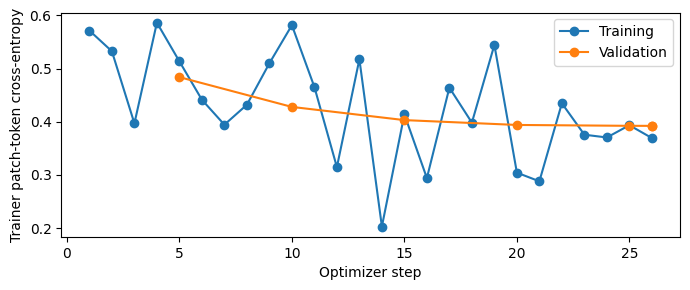

### Example: ACCUMULO-2102_testSetInstance_HdfsZooInstance_Explicit
Selection: lowest location-aware F1. Display excerpts only.

base


```diff
diff --git a/core/src/test/java/org/apache/accumulo/core/util/shell/ShellSetInstanceTest.java b/core/src/test/java/org/apache/accumulo/core/util/shell/ShellSetInstanceTest.java
index 1234567..89abcdef 100644
--- a/core/src/test/java/org/apache/accumulo/core/util/shell/ShellSetInstanceTest.java
+++ b/core/src/test/java/org/apache/accumulo/core/util/shell/ShellSetInstanceTest.java
@@ -100,7 +100,7 @@ public void testSetInstance_Fake() throws Exception {
     ShellOptionsJC opts = createMock(ShellOptionsJC.class);
     expect(opts.isFake()).andReturn(true);
     replay(opts);
-    MockInstance theInstance = createMock(MockInstance.class);
+    MockInstance theInstance = createMock(MockInstance.class, "fake");
     expectNew(MockInstance.class, "fake").andReturn(theInstance);
     replay(theInstance, MockInstance.class);

     shell.setInstance(opts);
@@ -166,7 +166,7 @@ public void testSetInstance_HdfsZooInstance_Explicit() throws Exception {
     testSetInstance_HdfsZooInstance(true, false, false);
   }
   @Test
   public void testSetInstance_HdfsZooInstance_InstanceGiven() throws Exception {
-    testSetInstance_HdfsZooInstance(false, true, false);
+    testSetInstance_HdfsZooInstance(false, true, false, "instance");
   }
   @Test
   public void testSetInstance_HdfsZooInstance_HostsGiven() throws Exception {
@@ -174,7 +174,7 @@ public void testSetInstance_HdfsZooInstance_HostsGiven() throws Exception {
     testSetInstance_HdfsZooInstance(false, false, true, "host3,host4");
   }
   @Test
   public void testSetInstance_HdfsZooInstance_Implicit() throws Exception {
-    testSetInstance_HdfsZooInstance(false, false, false);
+    testSetInstance_HdfsZooInstance(false, false, false, null);
   }
   
   private void testSetInstance_HdfsZooInstance(boolean explicitHdfs, boolean onlyInstance, boolean onlyHosts, String instanceName)
     throws Exception {
```

lora


diff -ruN Flaky/core/src/test/java/org/apache/accumulo/core/util/shell/ShellSetInstanceTest.java Fixed/core/src/test/java/org/apache/accumulo/core/util/shell/ShellSetInstanceTest.java
--- Flaky/core/src/test/java/org/apache/accumulo/core/util/shell/ShellSetInstanceTest.java	2023-01-11 15:01:01.000000000 +0100
+++ Fixed/core/src/test/java/org/apache/accumulo/core/util/shell/ShellSetInstanceTest.java	2023-01-11 15:01:01.000000000 +0100
@@ -100,7 +100,7 @@
     ShellOptionsJC opts = createMock(ShellOptionsJC.class);
     expect(opts.isFake()).andReturn(true);
     replay(opts);
-    MockInstance theInstance = createMock(MockInstance.class);
+    MockInstance theInstance = createMock(MockInstance.class, "fake");
     expectNew(MockInstance.class, "fake").andReturn(theInstance);
     replay(theInstance, MockInstance.class);
 
@@ -164,7 +164,7 @@
     ShellOptionsJC opts = createMock(ShellOptionsJC.class);
     expect(opts.isFake()).andReturn(false);
     expect(opts.getClientConfiguration()).andReturn(clientConf);
-    expect(opts.isHdfsZooInstance()).andReturn(explicitHdfs);
+    expect(opts.isHdfsZooInstance()).andReturn(explicitHdfs).anyTimes();
     if (!explicitHdfs) {
       expect(opts.getZooKeeperInstance())
         .andReturn(Collections.<String>emptyList());

Reference


... (12 outputs left out)

diff -ruN Flaky/graylog2-server/src/test/java/org/graylog2/contentpacks/model/entities/references/ValueReferenceTest.java Fixed/graylog2-server/src/test/java/org/graylog2/contentpacks/model/entities/references/ValueReferenceTest.java
--- Flaky/graylog2-server/src/test/java/org/graylog2/contentpacks/model/entities/references/ValueReferenceTest.java	2020-05-15 15:01:01.000000000 +0600
+++ Fixed/graylog2-server/src/test/java/org/graylog2/contentpacks/model/entities/references/ValueReferenceTest.java	2020-05-15 15:01:01.000000000 +0600
@@ -109,7 +109,7 @@
         assertThat(objectMapper.writeValueAsString(ValueReference.of(true))).isEqualTo("{\"@type\":\"boolean\",\"@value\":true}");
         assertThat(objectMapper.writeValueAsString(ValueReference.of(false))).isEqualTo("{\"@type\":\"boolean\",\"@value\":false}");
     }
-    
+
     @Test
     public void deserializeBoolean() throws IOException {
         assertThat(objectMapper.readValue("{\"@type\":\"boolean\",\"@value\":true}", ValueReference.class)).isEqualTo(ValueReference.of(true));
@@ -120,7 +120,7 @@
         assertThat(objectMapper.readValue("{\"@type\":\"string\",\"@value\":\"B\"}", ValueReference.class)).isEqualTo(ValueReference.of(TestEnum.B));
     }
 
-    
+
     @Test
     public void serializeFloat() throws IOException {
         assertThat(objectMapper.writeValueAsString(ValueReference.of(1.0f))).isEqualTo("{\"@type\":\"float\",\"@value\":1.0}");
@@ -131,7 +131,7 @@
         assertThat(objectMapper.writeValueAsString(ValueReference.of(42.4f))).isEqualTo("{\"@type\":\"float\",\"@value\":42.4}");
     }
 
-    
+
     @Test
     @Ignore("FIXME: Jackson automatically deserializes floating point numbers as double")
     public void deserializeFloat() throws IOException {
@@ -142,7 +142,7 @@
         assertThat(objectMapper.readValue("{\"@type\":\"float\",\"@value\":1.0}", ValueReference.class)).isEqualTo(ValueReference.of(1.0f));
         assertThat(objectMapper.readValue("{\"@type\":\"float\",\"@value\":42.4}", ValueReference.class)).isEqualTo(ValueReference.of(42.4f));
     }
-    
+
     @Test
     public void serializeInteger() throws IOException {
         assertThat(objectMapper.writeValueAsString(ValueReference.of(1))).isEqualTo("{\"@type\":\"integer\",\"@value\":1}");
@@ -153,7 +153,7 @@
         assertThat(objectMapper.writeValueAsString(ValueReference.of(42))).isEqualTo("{\"@type\":\"integer\",\"@value\":42}");
     }
 
-    
+
     @Test
     public void deserializeInteger() throws IOException {
         assertThat(objectMapper.readValue("{\"@type\":\"integer\",\"@value\":1}", ValueReference.class)).isEqualTo(ValueReference.of(1));
@@ -164,7 +164,7 @@
         assertThat(objectMapper.readValue("{\"@type\":\"integer\",\"@value\":42}", ValueReference.class)).isEqualTo(ValueReference.of(42));
     }
 
-    
+
     @Test
     public void serializeString() throws IOException {
         assertThat(objectMapper.writeValueAsString(ValueReference.of(""))).isEqualTo("{\"@type\":\"st

Reference


diff -ruN Flaky/graylog2-server/pom.xml Fixed/graylog2-server/pom.xml
--- Flaky/graylog2-server/pom.xml	2025-06-23 22:02:06.193564809 +0600
+++ Fixed/graylog2-server/pom.xml	2025-06-23 22:02:07.161495147 +0600
@@ -635,6 +635,12 @@
             <artifactId>jersey-test-framework-provider-inmemory</artifactId>
             <scope>test</scope>
         </dependency>
+        <dependency>
+            <groupId>org.skyscreamer</groupId>
+            <artifactId>jsonassert</artifactId>
+            <version>1.5.0</version>
+            <scope>test</scope>
+        </dependency>
     </dependencies>
 
     <build>
diff -ruN Flaky/graylog2-server/src/test/java/org/graylog2/contentpacks/model/entities/references/ValueReferenceTest.java Fixed/graylog2-server/src/test/java/org/graylog2/contentpacks/model/entities/references/ValueReferenceTest.java
--- Flaky/graylog2-server/src/test/java/org/graylog2/contentpacks/model/entities/references/ValueReferenceTest.java	2025-06-23 22:02:06.281558466 +0600
+++ Fixed/graylog2-server/src/test/java/org/graylog2/contentpacks/model/entities/references/ValueReferenceTest.java	2025-06-23 22:02:07.248488932 +0600
@@ -19,8 +19,10 @@
 import com.fasterxml.jackson.databind.JsonMappingException;
 import com.fasterxml.jackson.databind.ObjectMapper;
 import org.graylog2.shared.bindings.providers.ObjectMapperProvider;
+import org.json.JSONException;
 import org.junit.Ignore;
 import org.junit.Test;
+import org.skyscreamer.jsonassert.JSONAssert;
 
 import java.io.IOException;
 import java.util.Collections;
@@ -31,6 +33,14 @@
 public class ValueReferenceTest {
     private final ObjectMapper objectMapper = new ObjectMapperProvider().get();
 
+    public void assertJsonEqualsNonStrict(String json1, String json2) {
+        try {
+            JSONAssert.assertEquals(json1, json2, false);
+        } catch (JSONException jse) {
+            throw new IllegalArgumentException(jse.getMessage());
+        }
+    }
+
     @Test
     public void asBoolean() {
         assertThat(ValueReference.of(true).asBoolean(Collections.emptyMap())).isEqualTo(Boolean.TRUE);
@@ -107,8 +117,8 @@
 
     @Test
     public void serializeBoolean() throws IOException {
-        assertThat(objectMapper.writeValueAsString(ValueReference.of(true))).isEqualTo("{\"@type\":\"boolean\",\"@value\":true}");
-        assertThat(objectMapper.writeValueAsString(ValueReference.of(false))).isEqualTo("{\"@type\":\"boolean\",\"@value\":false}");
+        assertJsonEqualsNonStrict(objectMapper.writeValueAsString(ValueReference.of(true)), "{\"@type\":\"boolean\",\"@value\":true}");
+        assertJsonEqualsNonStrict(objectMapper.writeValueAsString(ValueReference.of(false)), "{\"@type\":\"boolean\",\"@value\":false}");
     }
 
     @Test
@@ -119,8 +129,8 @@
 
     @Test
     public void serializeEnum() throws IOException {
-        assertThat(objectMapper.writeValueAsString(ValueReference.of(TestEnum.A))).isEqualTo("{\"@type\":\"string\",\"@value\":\"A\"}");
-        assertThat(ob

Observed full-cohort normalized patch agreement: base=0.000, fine-tuned=0.000. These are structural agreement rates, not execution-validated repairs.
Budget-constrained references: 6 of 61
Matched token-weighted validation CE difference (LoRA minus base): -0.12210364173679289
Behavioral Maven repair validation: not measured in this notebook.
Drive run directory: /content/drive/MyDrive/reproflake/runs/qwen3b-20261124T042359


In [32]:
import matplotlib.pyplot as plt
from IPython.display import Code, Markdown

train_metrics = read_json(training_dir / "train_results.json")
validation_metrics = read_json(training_dir / "eval_results.json")
resources = read_json(training_dir / "resources.json")
likelihood = read_json(comparison_dir / "validation_likelihood.json")
display(
    pd.DataFrame(
        [
            {
                "trainer_training_loss": train_metrics["train_loss"],
                "trainer_validation_loss": validation_metrics["eval_loss"],
                "matched_base_validation_CE": likelihood["base"]["cross_entropy"],
                "matched_lora_validation_CE": likelihood["lora"]["cross_entropy"],
                "trainer_seconds": train_metrics["train_runtime"],
                "load_through_validation_seconds": resources[
                    "load_through_validation_seconds"
                ],
                "peak_training_reserved_GiB": resources["peak_cuda_reserved_bytes"]
                / 1024**3,
            }
        ]
    )
)
for cohort in ("all_prepared", "budget_feasible"):
    print(cohort)
    if comparison["cohorts"]["base"][cohort]["status"] == "no_cases":
        print("No cases in this cohort; metrics are not measured.")
        continue
    for group in ("case_mean", "archive_macro_mean", "project_macro_mean"):
        print(group)
        display(
            pd.DataFrame(
                {
                    arm: comparison["cohorts"][arm][cohort][group]
                    for arm in ("base", "lora")
                }
            )
        )
    interval = comparison["project_paired_intervals"][cohort]
    if interval["status"] == "measured":
        display(pd.DataFrame(interval["intervals"]).T)
    else:
        print("Confidence intervals:", interval["status"])
display(
    pd.DataFrame(
        {
            arm: {
                key: comparison["models"][arm][key]
                for key in (
                    "cases",
                    "archives",
                    "projects",
                    "references_exceeding_generation_budget",
                )
            }
            for arm in ("base", "lora")
        }
    )
)
display(
    pd.DataFrame(
        {
            arm: read_json(comparison_dir / f"{arm}_generation_resources.json")
            for arm in ("base", "lora")
        }
    )
)
logs = read_jsonl(training_dir / "metrics.jsonl")
figure, axis = plt.subplots(figsize=(7, 3))
for key, label in (("loss", "Training"), ("eval_loss", "Validation")):
    points = [(row["step"], row[key]) for row in logs if key in row]
    if points:
        axis.plot(*zip(*points), marker="o", label=label)
axis.set(xlabel="Optimizer step", ylabel="Trainer patch-token cross-entropy")
axis.legend()
plt.tight_layout()
plt.show()

raw = {
    arm: {row["case_id"]: row for row in predictions}
    for arm, predictions in (("base", base_predictions), ("lora", lora_predictions))
}
ranked = sorted(
    case_scores["lora"],
    key=lambda row: (row["located_changed_line_f1"], row["case_id"]),
)
selected = [
    ("lowest location-aware F1", ranked[0]),
    ("highest location-aware F1", ranked[-1]),
]
limited = next((row for row in ranked if row["hit_token_limit"]), None)
if limited is not None:
    selected.append(("token-limited output", limited))
shown = set()
for criterion, row in selected:
    case = row["case_id"]
    if case in shown:
        continue
    shown.add(case)
    display(
        Markdown(f"### Example: {case}\nSelection: {criterion}. Display excerpts only.")
    )
    for arm in ("base", "lora"):
        print(arm)
        display(Code(raw[arm][case]["patch"][:3000], language="diff"))
    print("Reference")
    display(Code(targets[row["archive_id"]][:3000], language="diff"))
full = comparison["models"]
print(
    "Observed full-cohort normalized patch agreement:",
    f"base={full['base']['case_mean']['normalized_patch_match']:.3f},",
    f"fine-tuned={full['lora']['case_mean']['normalized_patch_match']:.3f}.",
    "These are structural agreement rates, not execution-validated repairs.",
)
print(
    "Budget-constrained references:",
    full["base"]["references_exceeding_generation_budget"],
    "of",
    full["base"]["cases"],
)
print(
    "Matched token-weighted validation CE difference (LoRA minus base):",
    likelihood["lora_minus_base_ce"],
)
print("Behavioral Maven repair validation: not measured in this notebook.")
print("Drive run directory:", RUN)

## References

- [ReproFlake dataset](https://doi.org/10.5281/zenodo.17508466)
- [Qwen2.5-Coder-3B-Instruct](https://huggingface.co/Qwen/Qwen2.5-Coder-3B-Instruct)
- [Pinned NF4 checkpoint](https://huggingface.co/unsloth/Qwen2.5-Coder-3B-Instruct-bnb-4bit/tree/84f4805873850233fe5b2b156d3e3435425b4098)
- [Unsloth](https://github.com/unslothai/unsloth)